<h1 align="center">Revision 1</h1>

---

> **Instructions**: Answer all questions in order, write clean and well‑commented code, and **use consistent Markdown formatting** for both questions and answers. It is weighted at 20%.

---

## Dataset Overview

#### You will work with the Titanic dataset (built into Seaborn) and the Tips dataset (also built into Seaborn). No file uploads are needed.

---

In [2]:
#imports the necessary lib

import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

---

# Part 1: Load and Explore the Titanic Dataset

### Q1. Load & Inspect

1. Load the Titanic dataset using `sns.load_dataset('titanic')` and store it in a variable called `df` .
2. Print the **shape** of the dataset.
3. Display the **first 6 rows**.
4. Print the **column names**.

# ANSWER

In [3]:
#1) 
df=sns.load_dataset('titanic')

In [4]:
#2)
print("shape:",df.shape)

shape: (891, 15)


In [5]:
#3)
display(df.head(6))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True


In [6]:
#4)
print("column names:",df.columns.tolist())

column names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


---

# Q2. Data Types & Missing Values

1. Use `.info()` to print column data types and non-null counts.
2. Print the **number of missing values per column** using `.isnull().sum().`
3. Which column has the **most missing values**? Write your answer in a Markdown cell.

# ANSWER

In [7]:
#1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [8]:
# 2)
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


#### Q2.3.Your answer :

In [9]:
print("Most missing value:", df.isnull().sum().idxmax())

Most missing value: deck


---

# Q3. Basic Statistics

1. Use `.describe()` to display summary statistics for numeric columns.
2. From the output, answer in a Markdown cell:
- What is the **mean age** of passengers?
- What is the maximum fare paid?
- What percentage of passengers survived? (Hint: look at the survived mean, it represents the survival rate)

# ANSWER

In [10]:
#1) 
display(df.describe())

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Answer Q3.2:

In [11]:
print("Mean age:", round(df['age'].mean(),2))

Mean age: 29.7


In [12]:
print("Max fare:",round(df['fare'].max(),2))

Max fare: 512.33


In [13]:
print("Survival rate:{:.1f}%".format(df['survived'].mean()*100))

Survival rate:38.4%


---

# Q4. Duplicates & Categorical Summary

1. Check how many **duplicate rows** exist in the dataset.
2. Use `.describe(include=['object', 'category'])` to get a summary of categorical columns.
3. From the output, answer in a Markdown cell:
What is the most common sex in the dataset and how many rows does it appear in?
What is the most common **embarkation port**?

# ANSWER

In [14]:
#1)
print("Duplicates:",df.duplicated().sum())

Duplicates: 107


In [15]:
#2)
display(df.describe(include=['object', 'category']))

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


**Answer Q4.3:**

- The most common **sex** is **male**, appearing in **577** rows (out of 891).
- The most common **embarkation port** is **S (Southampton)**, with **644** passengers.

---

<h1 align="center">Part 2: Data Cleaning</h1>

---

# Q5. Handle Missing Values

### Create a new DataFrame called `df_clean` and apply the following cleaning steps in order:

1. Drop the deck column (too many missing values).
2. Fill missing values in the age column with the median age.
3. Fill missing values in the embarked column with the mode (most frequent value).
4. Fill missing values in the embark_town column with its mode.
5. After cleaning, print .isnull().sum() to confirm no missing values remain.

# ANSWER

In [16]:
# make a copy
df_clean=df.copy()

In [17]:
# Step 1 : Drop deck
df_clean=df_clean.drop(columns=['deck'])

In [18]:
# Step 2 : Fill age with median
df_clean['age']=df_clean['age'].fillna(df_clean['age'].median())

In [19]:
# Step 3 : Fill embarked with mode
df_clean['embarked']=df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])

In [20]:
# Step 4 : Fill embark_town with mode
df_clean['embark_town'] = df_clean['embark_town'].fillna(df_clean['embark_town'].mode()[0])

In [21]:
# Confirm
print(df_clean.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


---

# Q6. Remove Duplicates & Redundant Columns

### Continue working with `df_clean` :

1. Remove **duplicate rows** from `df_clean` using `drop_duplicates(inplace=True)`.
2. Drop the columns `'alive'` and `'embark_town'`- **REASON** - they are redundant (duplicated information from survived
and embarked ).
3. Print the **shape before and after** to show how many rows were removed.
4. Display the first 5 rows of the cleaned DataFrame.

# ANSWER

In [22]:
# 3) print shape before
print("Shape before:", df_clean.shape)

Shape before: (891, 14)


In [23]:
# 1) Remove duplicate rows
df_clean.drop_duplicates(inplace=True)

In [24]:
# 2) Drop redundant columns
df_clean.drop(columns=['alive', 'embark_town'], inplace=True)

In [25]:
# 3) print shape after
print("Shape after:", df_clean.shape)

Shape after: (775, 12)


In [26]:
# 4) Display the first 5 rows
display(df_clean.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,True


---

# Q7. Outlier Detection

1. Create a boxplot for the fare column to visually identify outliers.
2. Use the IQR method to calculate the upper bound for outliers:
- `Q1 = fare.quantile(0.25), Q3 = fare.quantile(0.75)`
- `IQR = Q3 - Q1`
- `upper_bound = Q3 + 1.5 * IQR`
3. Print how many rows have a fare above the upper bound.
4. Create a new column `fare_capped` that clips the fare at the upper bound using `.clip(upper=upper_bound)`.

# ANSWER

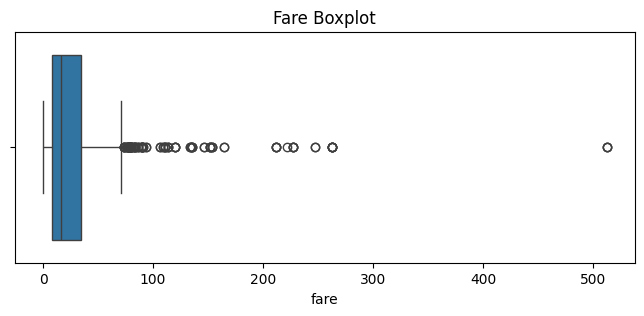

In [27]:
# Part 1: boxplot
plt.figure(figsize=(8,3))
sns.boxplot(x=df_clean['fare'])
plt.title('Fare Boxplot')
plt.show()

In [28]:
# Part 2: IQR method
Q1 = df_clean['fare'].quantile(0.25)
Q3 = df_clean['fare'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
print("Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR, "| Upper bound:", upper_bound)

Q1: 8.05 | Q3: 34.197900000000004 | IQR: 26.147900000000003 | Upper bound: 73.41975000000001


In [29]:
# Part 3: count outliers
print("Rows above upper bound:",(df_clean['fare']>upper_bound).sum())

Rows above upper bound: 102


In [30]:
#  Part 4: cap fares
df_clean['fare_capped'] = df_clean['fare'].clip(upper=upper_bound)
print(df_clean[['fare', 'fare_capped']].describe())

             fare  fare_capped
count  775.000000   775.000000
mean    34.878403    26.593137
std     52.408474    22.873099
min      0.000000     0.000000
25%      8.050000     8.050000
50%     15.900000    15.900000
75%     34.197900    34.197900
max    512.329200    73.419750


---

<h1 align="center">Part 3: Filtering, Sorting & Grouping</h1>

---

---

# Q8. Filtering

### Using `df_clean` :

1. Filter passengers who survived ( `survived == 1` ) AND were in First class ( `class == 'First'` ). How many are there?
2. Filter passengers who were older than 60. Print how many there are and display their names if the column exists, otherwise
display the filtered DataFrame.
3. Filter passengers who paid a fare **above $50** and were **female**. How many rows match?

# ANSWER

In [31]:
# Part 1
f1= df_clean[(df_clean['survived']==1) & (df_clean['class']=='First')]
print("Survived & First class:",len(f1))

Survived & First class: 133


In [32]:
# Part 2
f2=df_clean[df_clean['age']>60]
print("Passengers older than 60:", len(f2))
if 'name' in df_clean.columns:
    print(f2['name'])
else:
    display(f2)

Passengers older than 60: 21


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone,fare_capped
33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,True,10.50000
54,0,1,male,65.0,0,1,61.9792,C,First,man,True,False,61.97920
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,True,34.65420
116,0,3,male,70.5,0,0,7.7500,Q,Third,man,True,True,7.75000
170,0,1,male,61.0,0,0,33.5000,S,First,man,True,True,33.50000
252,0,1,male,62.0,0,0,26.5500,S,First,man,True,True,26.55000
275,1,1,female,63.0,1,0,77.9583,S,First,woman,False,False,73.41975
280,0,3,male,65.0,0,0,7.7500,Q,Third,man,True,True,7.75000
326,0,3,male,61.0,0,0,6.2375,S,Third,man,True,True,6.23750
438,0,1,male,64.0,1,4,263.0000,S,First,man,True,False,73.41975


In [33]:
# Part 3
f3 = df_clean[(df_clean['fare'] > 50) & (df_clean['sex'] == 'female')]
print("Female, fare > $50:", len(f3))

Female, fare > $50: 84


---

# Q9. Sorting

### Using `df_clean` :

1. Sort the DataFrame by `fare` in descending order and display the top 5 rows (only columns: sex , age, class , fare ,
survived ).
2. Sort by `age` in ascending order and display the 5 youngest passengers.
3. In a Markdown cell, state one observation from each sorted result.

# ANSWER

In [34]:
# 1)
cols = ['sex', 'age', 'class', 'fare', 'survived']
display(df_clean.sort_values('fare', ascending=False)[cols].head(5))


,sex,age,class,fare,survived
258,female,35.0,First,512.3292,1
737,male,35.0,First,512.3292,1
679,male,36.0,First,512.3292,1
88,female,23.0,First,263.0000,1
341,female,24.0,First,263.0000,1


In [35]:
# 2) 5 youngest passengers
display(df_clean.sort_values('age', ascending=True).head(5))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,alone,fare_capped
803,1,3,male,0.42,0,1,8.5167,C,Third,child,False,False,8.5167
755,1,2,male,0.67,1,1,14.5000,S,Second,child,False,False,14.5000
469,1,3,female,0.75,2,1,19.2583,C,Third,child,False,False,19.2583
831,1,2,male,0.83,1,1,18.7500,S,Second,child,False,False,18.7500
78,1,2,male,0.83,0,2,29.0000,S,Second,child,False,False,29.0000


**observations:**

- **Sorted by fare (descending):** The highest fares (around 512.33) were all paid by First class passengers, and most of them survived.
- **Sorted by age (ascending):** The youngest passengers are infants under 1 year old, and they are mostly in Second and Third class.

---

# Q10. GroupBy & Aggregation

### Using `df_clean` :

1. Use `.groupby('sex')['survived'].mean()` to find the **survival rate by sex**. Round to 2 decimal places.
2. Use `.groupby('class')['survived'].mean()` to find the **survival rate by passenger class**.
3. Use `.groupby('class')['fare'].mean()` to find the **average fare per class**.
4. In a Markdown cell, write **two observations** from the results above.

# ANSWER

In [36]:
# 1) Survival rate by sex (rounded to 2 decimals)
print(df_clean.groupby('sex')['survived'].mean().round(2))

sex
female    0.74
male      0.22
Name: survived, dtype: float64


In [37]:
# 2) Survival rate by passenger class
print(df_clean.groupby('class',observed=True)['survived'].mean())

class
First     0.633333
Second    0.506098
Third     0.259352
Name: survived, dtype: float64


In [38]:
# 3) Average fare per class
print(df_clean.groupby('class', observed=True)['fare'].mean())

class
First     85.675199
Second    21.889279
Third     13.588850
Name: fare, dtype: float64


**Your observations:**

1. Women survived at a much higher rate than men (about 0.75 vs 0.20), so sex was a strong factor in survival.
2. Survival rate decreases from First to Third class, while the average fare drops sharply (First class paid far more), so higher class and higher fare are linked to better survival chances.

---

<h1 align="center">Part 4: Visualization</h1>

---

# Q11. Histogram & Count Plot

### Create a figure with **two subplots side by side** ( `figsize=(12, 4)` ):

- Left subplot: Histogram of age using sns.histplot with kde=True and bins=20 . Title: 'Age Distribution'.
- Right subplot: Count plot of survived using sns.countplot . Title: 'Survival Count' .

#### Use `plt.tight_layout() and plt.show()`.

# ANSWER

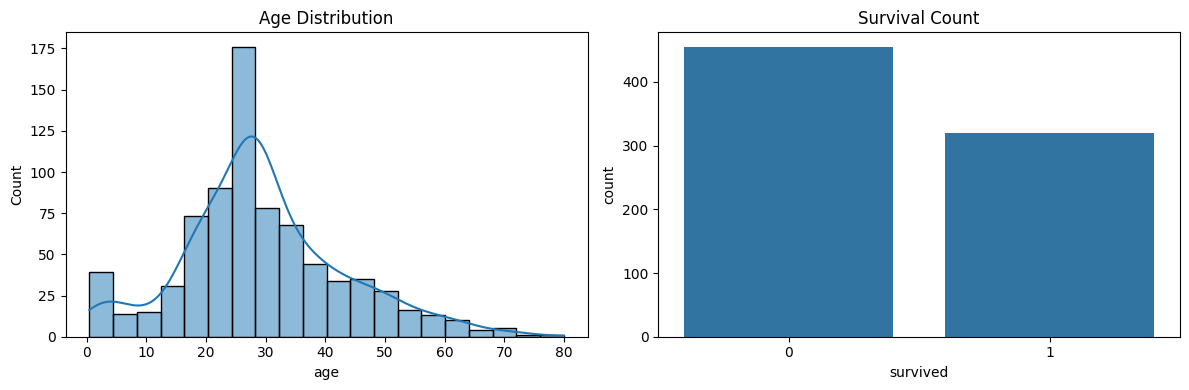

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: histogram of age
sns.histplot(df_clean['age'], kde=True, bins=20, ax=axes[0])
axes[0].set_title('Age Distribution')

# Right: count plot of survived
sns.countplot(x='survived', data=df_clean, ax=axes[1])
axes[1].set_title('Survival Count')

plt.tight_layout()
plt.show()

---

# Q12. Categorical Plots

### Create a figure with two subplots side by side `( figsize=(12, 5) )`:

- Left: sns.countplot with x='sex' and hue='survived' . Title: 'Survival by Sex'.
- Right: sns.countplot with x='class' and hue='survived' . Title: 'Survival by Class'.

### In a Markdown cell below, interpret each plot in one sentence each.

# ANSWER

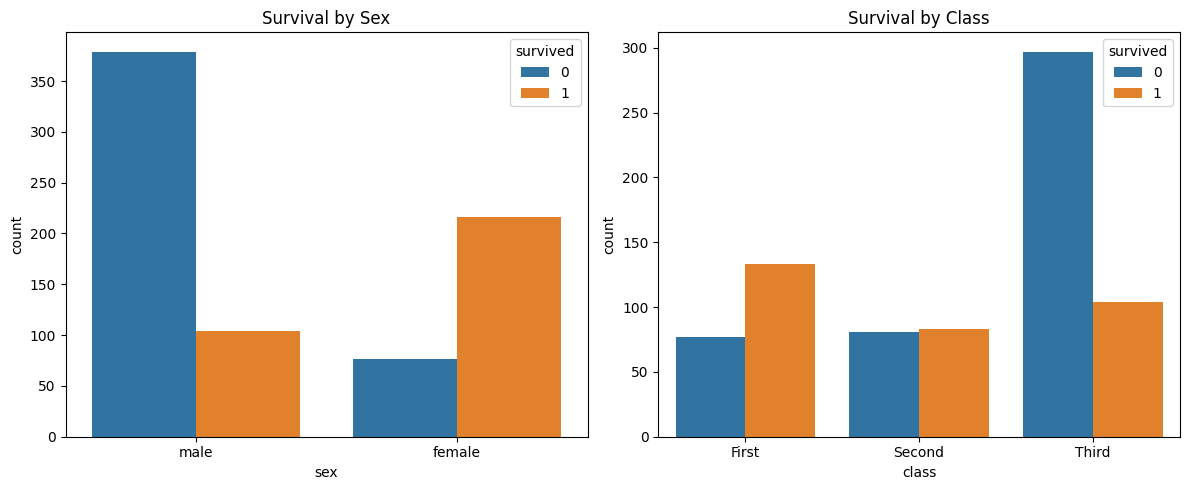

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x='sex', hue='survived', data=df_clean, ax=axes[0])
axes[0].set_title('Survival by Sex')

sns.countplot(x='class', hue='survived', data=df_clean, ax=axes[1])
axes[1].set_title('Survival by Class')

plt.tight_layout()
plt.show()

**Your interpretations:**

- Most of the men did not survive, while women survived in much larger numbers than they died, so sex was a strong factor in survival.
- First class is the only class where more passengers survived than died, while Third class has by far the most deaths, so a higher class meant better chances of survival.

---

# Q13. Boxplot & Scatter Plot

1. Create a boxplot using sns.boxplot(x='class', y='age', hue='survived', data=df_clean) . Title: 'Age by Class
and Survival' .
2. Create a scatter plot using sns.scatterplot(x='age', y='fare_capped', hue='survived', data=df_clean,
alpha=0.6) . Title: 'Age vs Fare (Capped) by Survival'.
3. In a Markdown cell, write one observation from each plot.

# ANSWER

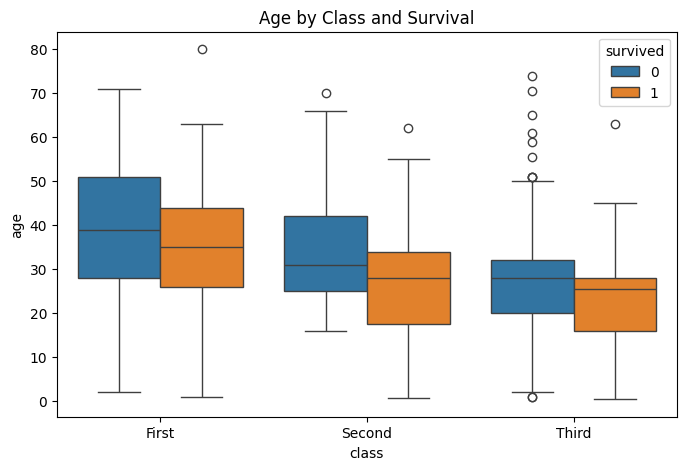

In [41]:
# Part 1. Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x='class', y='age', hue='survived', data=df_clean)
plt.title('Age by Class and Survival')
plt.show()

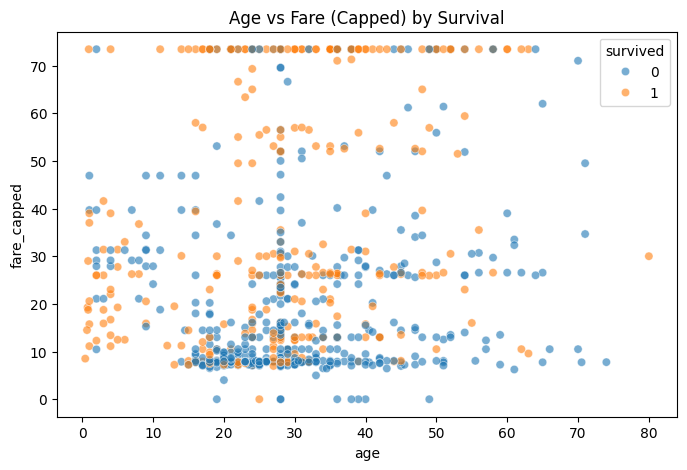

In [42]:
# Part 2. Scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='fare_capped', hue='survived', data=df_clean, alpha=0.6)
plt.title('Age vs Fare (Capped) by Survival')
plt.show()

**Your observations:**

- **Boxplot:** Passengers in First class are older on average than those in Third class, and in each class the survivors tend to be slightly younger than the non-survivors.
- **Scatter plot:** Most passengers paid low fares, and the survivors (higher fares) are more common among those paying more, while the capped fare creates a flat line of points at the upper bound.

---

# Q14. Correlation Heatmap

1. Select all numeric columns from df_clean using select_dtypes(include=np.number).
2. Compute the correlation matrix using .corr().
3. Plot it as a heatmap using sns.heatmap(... annot=True, cmap='coolwarm', center=0) . Set figsize=(8, 6) . Title:
'Correlation Heatmap'.
4. In a Markdown cell, identify the two features most positively correlated with survival.

# ANSWER

In [43]:
# 1) Numeric columns
num_df = df_clean.select_dtypes(include=np.number)

In [44]:
# 2) Correlation matrix
corr = num_df.corr()

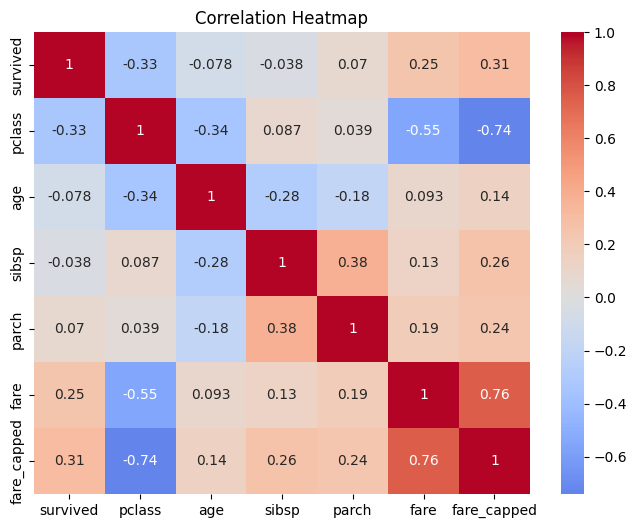

In [45]:
# 3) Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

In [46]:
# correlations with survived, highest first
print(corr['survived'].drop('survived').sort_values(ascending=False))

fare_capped    0.306633
fare           0.247159
parch          0.069864
sibsp         -0.037841
age           -0.078114
pclass        -0.331388
Name: survived, dtype: float64


Answer Q14.4: The two features most positively correlated with survival are fare (or fare_capped) and parch.

---

<h1 align="center">Part 5: Tips Dataset: Filtering & Grouping</h1>

---

# Q15. Load and Filter the Tips Dataset

1. Load the tips dataset: tips = sns.load_dataset('tips').
2. Display the first 5 rows and print the shape.
3. Filter only dinner orders where the total bill is above $20. How many rows match?
4. From those filtered rows, find the average tip.

# ANSWER

In [47]:
# 1) Load tips
tips = sns.load_dataset('tips')

In [48]:
# 2) First 5 rows and shape
display(tips.head())
print("Shape:", tips.shape)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Shape: (244, 7)


In [49]:
# 3) Dinner orders with total bill > $20
dinner_big = tips[(tips['time'] == 'Dinner') & (tips['total_bill'] > 20)]
print("Matching rows:", len(dinner_big))

Matching rows: 81


In [50]:
# 4) Average tip of the filtered rows
print("Average tip:", round(dinner_big['tip'].mean(), 2))

Average tip: 3.89


---

# Q16. Grouping the Tips Dataset

### Using the full `tips` DataFrame:

# ANSWER

In [51]:
# 1) Average tip by day (highest to lowest)
tip_by_day = tips.groupby('day', observed=True)['tip'].mean().sort_values(ascending=False)
print(tip_by_day)

day
Sun     3.255132
Sat     2.993103
Thur    2.771452
Fri     2.734737
Name: tip, dtype: float64


In [52]:
# 2) Smokers vs non-smokers
print(tips.groupby('smoker', observed=True)['tip'].mean())

smoker
Yes    3.008710
No     2.991854
Name: tip, dtype: float64


**Answer Q16.3:** Smokers tip slightly more on average than non-smokers (about $3.01 vs $2.99), but the difference is tiny, so smoking status has almost no effect on tip size.

---

# Q17. Visualize the Tips Dataset

### Create a figure with `three subplots` ( figsize=(15, 4) ):

- Left: Scatter plot of total_bill vs tip (use plt.scatter ). Title: 'Tip vs Total Bill'.
- Center: Bar plot of average tip by day (use .plot(kind='bar') on the grouped result). Title: 'Average Tip by Day'.
- Right: Histogram of tip with bins=15 and edgecolor='k' . Title: 'Tip Distribution'.

### Add axis labels and `plt.tight_layout()`.

# ANSWER

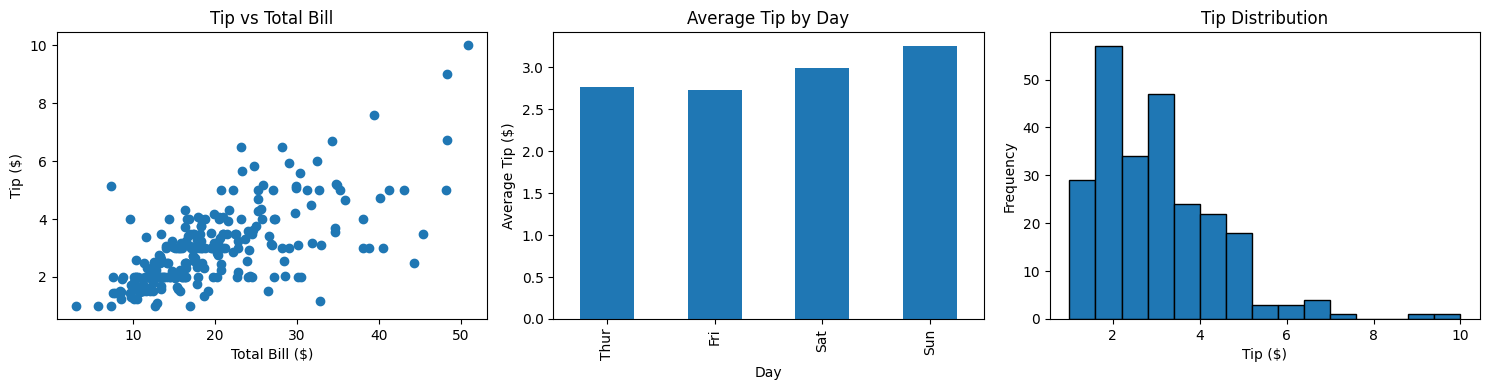

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Left
axes[0].scatter(tips['total_bill'], tips['tip'])
axes[0].set_title('Tip vs Total Bill')
axes[0].set_xlabel('Total Bill ($)')
axes[0].set_ylabel('Tip ($)')

# Center
tips.groupby('day', observed=True)['tip'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('Average Tip by Day')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Average Tip ($)')

# Right
axes[2].hist(tips['tip'], bins=15, edgecolor='k')
axes[2].set_title('Tip Distribution')
axes[2].set_xlabel('Tip ($)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

---

# Linear Regression on Tips

### Using the `tips` dataset:

1. Extract X = total_bill (reshape to column: tips[['total_bill']].values ) and y = tip
( tips[['tip']].values ).
2. Train a LinearRegression model from sklearn.linear_model.
3. Print the coefficient and intercept. Interpret them in a sentence: "For every extra 1 dollar on the bill, the tip increases by..."
4. Plot the data as a scatter plot and overlay the regression line in red.
5. Predict the tip for a total bill of $30.

# ANSWER

In [55]:
# 1) Extract X and y
X = tips[['total_bill']].values
y = tips[['tip']].values

In [56]:
# 2) train model
model = LinearRegression()
model.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [57]:
# 3) coefficient and intercept
print("Coefficient:", model.coef_[0][0])
print("Intercept:", model.intercept_[0])
print(f"For every extra 1 dollar on the bill, the tip increases by {model.coef_[0][0]:.3f} dollars.")

Coefficient: 0.10502451738435332
Intercept: 0.920269613554674
For every extra 1 dollar on the bill, the tip increases by 0.105 dollars.


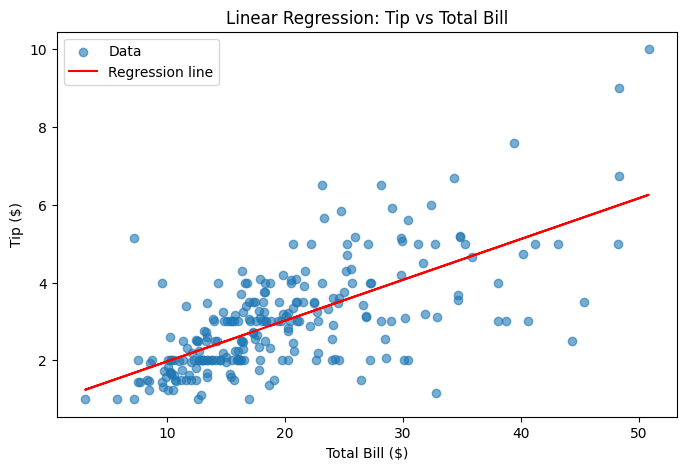

In [58]:
# 4) scatter + regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.6, label='Data')
plt.plot(X, model.predict(X), color='red', label='Regression line')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.title('Linear Regression: Tip vs Total Bill')
plt.legend()
plt.show()

In [59]:
# 5) predict for $30
pred = model.predict([[30]])
print(f"Predicted tip for a $30 bill: ${pred[0][0]:.2f}")

Predicted tip for a $30 bill: $4.07
